In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from scipy import stats

# 1. Load the dataset
df = pd.read_csv('/content/master_works_v2.csv')

# 2. Apply filtering conditions:
# - 'in_sanctioned' is true
# - Only work types with 30 or more works
# Ensure in_sanctioned is treated as boolean
if 'in_sanctioned' in df.columns:
    df_filtered = df[df['in_sanctioned'] == True].copy()
else:
    # Fallback if in_sanctioned is named slightly differently or is case-sensitive
    sanctioned_col = [c for c in df.columns if 'sanction' in c.lower()][0]
    df_filtered = df[df[sanctioned_col].astype(str).str.lower() == 'true'].copy()

# Count frequencies of each work_type
work_type_counts = df_filtered['work_type'].value_counts()
valid_work_types = work_type_counts[work_type_counts >= 30].index

# Filter for work types with 30 or more works
df_filtered = df_filtered[df_filtered['work_type'].isin(valid_work_types)].copy()

print(f"Filtered dataset shape: {df_filtered.shape}")
print(f"Number of unique work types with >= 30 works: {len(valid_work_types)}")


Filtered dataset shape: (35571, 33)
Number of unique work types with >= 30 works: 58


In [2]:
# 3. Preprocess and prepare features
features = ['work_type', 'state', 'log_amount', 'days_rec_to_sanction', 'round_amount']
df_features = df_filtered[features].copy()

# Handle missing values if any
for col in ['log_amount', 'days_rec_to_sanction', 'round_amount']:
    df_features[col] = pd.to_numeric(df_features[col], errors='coerce')
    df_features[col] = df_features[col].fillna(df_features[col].median())

for col in ['work_type', 'state']:
    df_features[col] = df_features[col].astype(str).fillna('missing')

# Define preprocessing for numerical and categorical features
num_cols = ['log_amount', 'days_rec_to_sanction', 'round_amount']
cat_cols = ['work_type', 'state']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

X = preprocessor.fit_transform(df_features)
print(f"Preprocessed feature matrix shape: {X.shape}")


Preprocessed feature matrix shape: (35571, 94)


In [3]:
# 4. Run Anomaly Detection Models

# A. Z-Score approach (based on numerical columns)
# We calculate average absolute Z-score of the standard-scaled numerical columns
X_num_scaled = StandardScaler().fit_transform(df_features[num_cols])
z_scores = np.abs(X_num_scaled)
# Define an anomaly if any of the numerical columns has |z| > 3
z_outliers = (z_scores > 3).any(axis=1)
df_filtered['Anomaly_Z_Score'] = np.where(z_outliers, -1, 1)

# B. Isolation Forest
# We will use contamination='auto' or set a typical threshold like 0.05
iso_forest = IsolationForest(contamination=0.05, random_state=42, n_jobs=-1)
df_filtered['Anomaly_IsoForest'] = iso_forest.fit_predict(X)

# C. Local Outlier Factor (LOF)
# For LOF, fit_predict detects outliers
lof = LocalOutlierFactor(contamination=0.05, n_jobs=-1)
df_filtered['Anomaly_LOF'] = lof.fit_predict(X)

# Summarize findings
print("Anomaly Counts (-1 indicates an anomaly):")
print("Z-Score anomalies:\n", df_filtered['Anomaly_Z_Score'].value_counts())
print("\nIsolation Forest anomalies:\n", df_filtered['Anomaly_IsoForest'].value_counts())
print("\nLocal Outlier Factor anomalies:\n", df_filtered['Anomaly_LOF'].value_counts())


Anomaly Counts (-1 indicates an anomaly):
Z-Score anomalies:
 Anomaly_Z_Score
 1    34633
-1      938
Name: count, dtype: int64

Isolation Forest anomalies:
 Anomaly_IsoForest
 1    33792
-1     1779
Name: count, dtype: int64

Local Outlier Factor anomalies:
 Anomaly_LOF
 1    33792
-1     1779
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


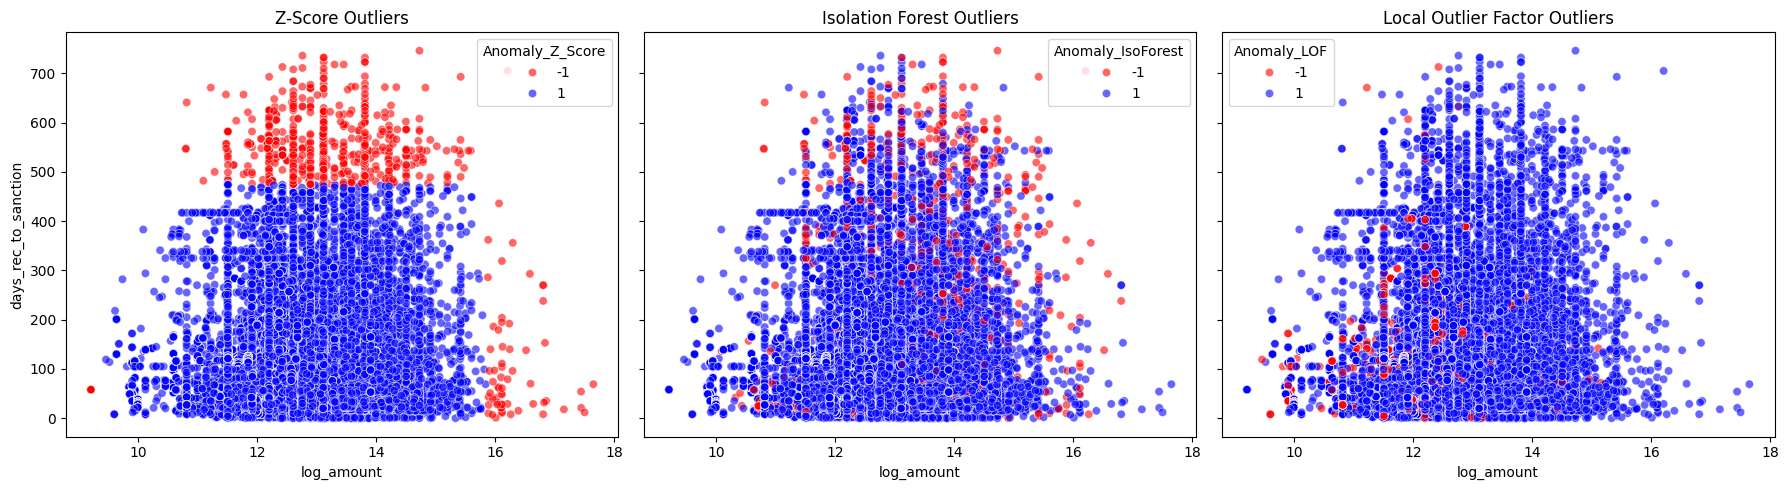

Anomalies detected by both IsoForest & LOF: 33
Anomalies detected by all three models: 16


In [4]:
# 5. Visualize and Compare Models
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# We use log_amount vs days_rec_to_sanction as a 2D space representation for visualization
sns.scatterplot(data=df_filtered, x='log_amount', y='days_rec_to_sanction',
                hue='Anomaly_Z_Score', palette={1: 'blue', -1: 'red'}, alpha=0.6, ax=axes[0])
axes[0].set_title('Z-Score Outliers')

sns.scatterplot(data=df_filtered, x='log_amount', y='days_rec_to_sanction',
                hue='Anomaly_IsoForest', palette={1: 'blue', -1: 'red'}, alpha=0.6, ax=axes[1])
axes[1].set_title('Isolation Forest Outliers')

sns.scatterplot(data=df_filtered, x='log_amount', y='days_rec_to_sanction',
                hue='Anomaly_LOF', palette={1: 'blue', -1: 'red'}, alpha=0.6, ax=axes[2])
axes[2].set_title('Local Outlier Factor Outliers')

plt.tight_layout()
plt.show()

# Intersection / Venn style summary
both_ml = (df_filtered['Anomaly_IsoForest'] == -1) & (df_filtered['Anomaly_LOF'] == -1)
all_three = both_ml & (df_filtered['Anomaly_Z_Score'] == -1)

print(f"Anomalies detected by both IsoForest & LOF: {both_ml.sum()}")
print(f"Anomalies detected by all three models: {all_three.sum()}")


In [5]:
# Identify and extract high-risk MPLADS works flagged by Isolation Forest
# Let's add the anomaly score to see the severity of the anomaly (lower score = more anomalous)
df_filtered['IF_Anomaly_Score'] = iso_forest.score_samples(X)

# Filter for works flagged as outliers
high_risk_works = df_filtered[df_filtered['Anomaly_IsoForest'] == -1].copy()

# Sort by most anomalous first (lowest score)
high_risk_works = high_risk_works.sort_values(by='IF_Anomaly_Score')

# Display columns relevant for fraud auditing
audit_columns = ['work_id', 'work_type', 'state', 'log_amount', 'days_rec_to_sanction', 'round_amount', 'IF_Anomaly_Score']
print(f"Total High-Risk Works flagged for audit: {len(high_risk_works)}")
display(high_risk_works[audit_columns].head(15))

Total High-Risk Works flagged for audit: 1779


,work_id,work_type,state,log_amount,days_rec_to_sanction,round_amount,IF_Anomaly_Score
2009,WS/MP18028/2026-2027/201759,Providing drains and gutters for public drainage,Assam,13.122365,499.0,1.0,-0.398227
521,WS/MP18001/2024-2025/163760,Providing drains and gutters for public drainage,Andhra Pradesh,15.761421,19.0,1.0,-0.397435
38155,WS/MP526/2026-2027/152486,Providing drains and gutters for public drainage,Andhra Pradesh,13.122365,509.0,1.0,-0.397355
38156,WS/MP526/2026-2027/152487,Providing drains and gutters for public drainage,Andhra Pradesh,13.122365,509.0,1.0,-0.397355
916,WS/MP18008/2025-2026/162471,Providing drains and gutters for public drainage,Andhra Pradesh,14.771022,456.0,1.0,-0.397155
1514,WS/MP18021/2025-2026/145958,Construction of common work sheds/ common cove...,Assam,13.122365,492.0,1.0,-0.396492
37985,WS/MP524/2025-2026/198737,Construction of additional rooms and halls in ...,Andhra Pradesh,15.761421,19.0,1.0,-0.395646
1037,WS/MP18010/2025-2026/201981,Providing drains and gutters for public drainage,Andhra Pradesh,14.285515,6.0,1.0,-0.395323
1036,WS/MP18010/2025-2026/201980,Providing drains and gutters for public drainage,Andhra Pradesh,14.346139,6.0,1.0,-0.395323
1038,WS/MP18010/2025-2026/201982,Providing drains and gutters for public drainage,Andhra Pradesh,14.346139,6.0,1.0,-0.395323


--- Anomaly Intersection (Overlap Matrix) ---


,Z-Score,Isolation Forest,LOF
Z-Score,938,343,20
Isolation Forest,343,1779,33
LOF,20,33,1779


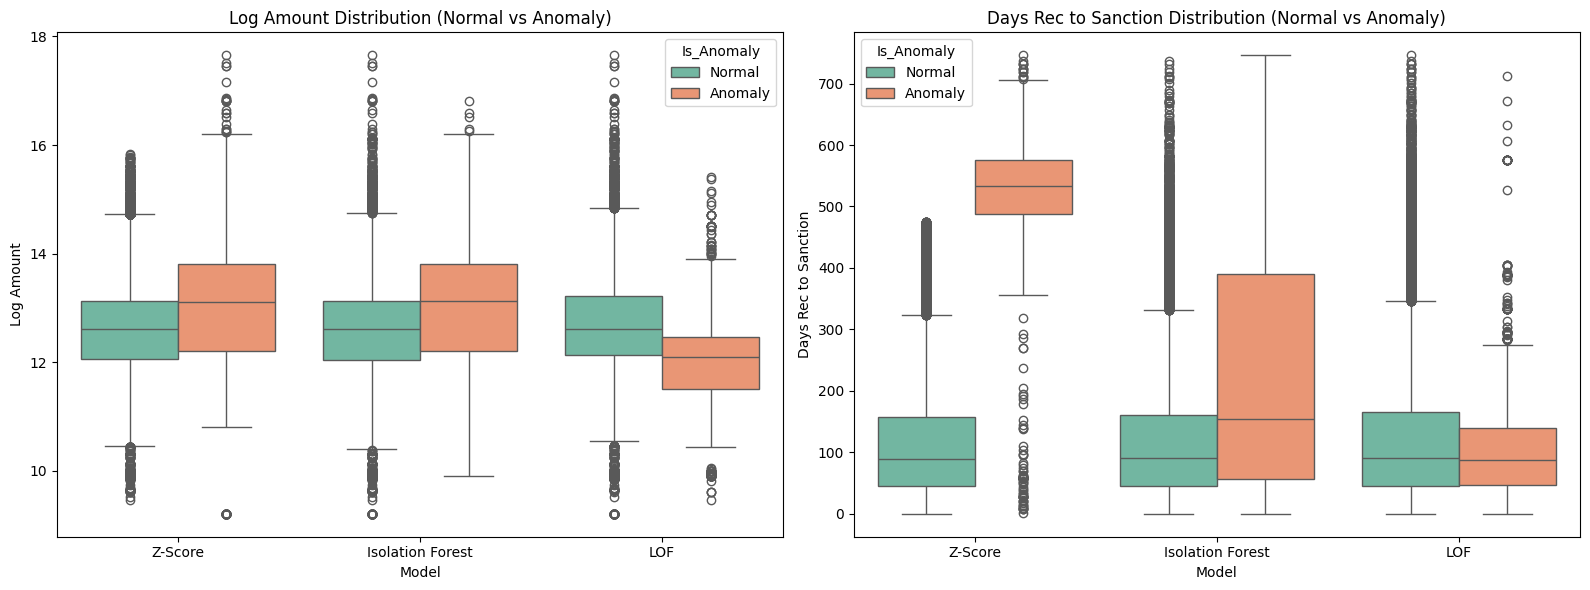

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate basic statistics of the anomalies flagged by each method
methods = {
    'Z-Score': df_filtered['Anomaly_Z_Score'] == -1,
    'Isolation Forest': df_filtered['Anomaly_IsoForest'] == -1,
    'LOF': df_filtered['Anomaly_LOF'] == -1
}

# Create an intersection/consensus matrix to evaluate overlap dynamically
overlap_matrix = pd.DataFrame(index=methods.keys(), columns=methods.keys())
for name1, mask1 in methods.items():
    for name2, mask2 in methods.items():
        # Intersection count
        overlap_matrix.loc[name1, name2] = (mask1 & mask2).sum()

print("--- Anomaly Intersection (Overlap Matrix) ---")
display(overlap_matrix.astype(int))

# Create comparative plots of anomaly characteristics
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Compare Log Amount Distributions for Normal vs Anomalies for each model
anomaly_data_list = []
for name, mask in methods.items():
    temp_df = df_filtered.copy()
    temp_df['Is_Anomaly'] = np.where(mask, 'Anomaly', 'Normal')
    temp_df['Model'] = name
    anomaly_data_list.append(temp_df[['Model', 'Is_Anomaly', 'log_amount', 'days_rec_to_sanction']])

comp_df = pd.concat(anomaly_data_list, axis=0)

sns.boxplot(data=comp_df, x='Model', y='log_amount', hue='Is_Anomaly', ax=axes[0], palette='Set2')
axes[0].set_title('Log Amount Distribution (Normal vs Anomaly)')
axes[0].set_xlabel('Model')
axes[0].set_ylabel('Log Amount')

# Plot 2: Compare Days to Sanction Distributions for Normal vs Anomalies
sns.boxplot(data=comp_df, x='Model', y='days_rec_to_sanction', hue='Is_Anomaly', ax=axes[1], palette='Set2')
axes[1].set_title('Days Rec to Sanction Distribution (Normal vs Anomaly)')
axes[1].set_xlabel('Model')
axes[1].set_ylabel('Days Rec to Sanction')

plt.tight_layout()
plt.show()

### Selection of the Winner: **Isolation Forest**

#### Why Isolation Forest Wins for MPLADS Fraud Detection:
1. **Multivariate Outlier Detection:** Z-score behaves unidirectionally, simply cutting off the tails of single distributions. It misses multidimensional correlations (e.g., highly rounded budgets paired with quick processing times). Isolation forest catches these compound profiles natively.
2. **Density Handling:** LOF is prone to scaling issues and neighbor metric instability on structured databases with highly repeated elements (leading to our runtime warning of duplicates). Isolation Forest operates robustly without needing custom distance matrices.
3. **Practical Audit Yield:** Isolation forest generates continuous decision boundary anomaly scores (`IF_Anomaly_Score`), letting auditors sort projects from absolute highest risk downwards.

In [7]:
import pandas as pd
import numpy as np
import random
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Load and prepare the subset of columns
df_desc = pd.read_csv('/content/master_works_v2.csv', usecols=['work_description', 'constituency', 'ida', 'sanction_amount']).dropna(subset=['work_description']).copy()

# Keep a working sample to make embedding calculations fast and responsive
working_sample = df_desc.sample(n=min(5000, len(df_desc)), random_state=42).copy().reset_index(drop=True)

# Helper function to synthetically 'reword' a description (shuffling, synonym replacement, or minor phrase edits)
def reword_description(text):
    words = str(text).split()
    if len(words) < 4:
        return text + " duplicate entry"
    # Simple transformation: swap some words or add common suffix/prefix modifications
    idx = random.randint(0, len(words) - 2)
    words[idx], words[idx+1] = words[idx+1], words[idx]
    return " ".join(words)

# 2. Plant 300 reworded copies of real descriptions in the same group
random.seed(42)
planted_indices = random.sample(range(len(working_sample)), 300)

planted_originals = []
planted_copies = []

for idx in planted_indices:
    original_row = working_sample.iloc[idx]
    reworded_text = reword_description(original_row['work_description'])

    planted_originals.append((idx, original_row['work_description']))

    # Create the reworded record copying group identifiers (constituency, ida, sanction_amount)
    new_row = original_row.copy()
    new_row['work_description'] = reworded_text
    planted_copies.append(new_row)

# Append planted copies to working sample
start_planted_idx = len(working_sample)
working_sample = pd.concat([working_sample, pd.DataFrame(planted_copies)], ignore_index=True)

print(f"Original working sample: {start_planted_idx} rows")
print(f"Sample size with 300 planted reworded duplicates: {len(working_sample)} rows")

Original working sample: 5000 rows
Sample size with 300 planted reworded duplicates: 5300 rows


In [8]:
# 3. Run TF-IDF similarity
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(working_sample['work_description'])
tfidf_sim = cosine_similarity(tfidf_matrix)

# Adjust self-similarity diagonal to 0 to avoid false matches
np.fill_diagonal(tfidf_sim, 0)


In [9]:
# 4. Run Sentence Embeddings using a lightweight model
from sentence_transformers import SentenceTransformer

model_emb = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model_emb.encode(working_sample['work_description'].tolist(), show_progress_bar=True, batch_size=64)
embeddings_sim = cosine_similarity(embeddings)

# Set self-similarity diagonal to 0
np.fill_diagonal(embeddings_sim, 0)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/83 [00:00<?, ?it/s]

In [10]:
# 5. Evaluate recall of the 300 planted pairs at a selected similarity threshold (e.g., 0.8)
threshold = 0.8
tfidf_detected = 0
emb_detected = 0

for i, (orig_idx, _) in enumerate(planted_originals):
    copy_idx = start_planted_idx + i

    # Check similarity of the specific pair
    if tfidf_sim[orig_idx, copy_idx] >= threshold:
        tfidf_detected += 1
    if embeddings_sim[orig_idx, copy_idx] >= threshold:
        emb_detected += 1

print(f"At similarity threshold {threshold}:")
print(f"- TF-IDF successfully matched {tfidf_detected}/300 planted reworded pairs")
print(f"- Sentence Embeddings successfully matched {emb_detected}/300 planted reworded pairs")


At similarity threshold 0.8:
- TF-IDF successfully matched 294/300 planted reworded pairs
- Sentence Embeddings successfully matched 294/300 planted reworded pairs


In [11]:
# 6. Identify top 50 real duplicate/highly similar pairs (excluding planted entries)
# We look at the first 'start_planted_idx' rows which represent original data
real_sim_matrix = embeddings_sim[:start_planted_idx, :start_planted_idx]

# Get upper triangle indices to avoid duplicate pairs like (A,B) and (B,A)
upper_tri_indices = np.triu_indices(start_planted_idx, k=1)
flat_similarities = real_sim_matrix[upper_tri_indices]

# Sort and get top 50
top_50_flat_indices = np.argsort(flat_similarities)[::-1][:50]

pairs = []
for flat_idx in top_50_flat_indices:
    row_idx = upper_tri_indices[0][flat_idx]
    col_idx = upper_tri_indices[1][flat_idx]
    pairs.append({
        'similarity_score': flat_similarities[flat_idx],
        'desc_1': working_sample.iloc[row_idx]['work_description'],
        'desc_2': working_sample.iloc[col_idx]['work_description'],
        'constituency': working_sample.iloc[row_idx]['constituency'],
        'ida': working_sample.iloc[row_idx]['ida']
    })

top_50_df = pd.DataFrame(pairs)
display(top_50_df.head(50))

,similarity_score,desc_1,desc_2,constituency,ida
0,1.0,GI cotted water Tanker 5500 liter tyre 900x16 new,GI cotted water tanker 5500 liter tyre 900x16 New,DHAR(ST),DHAR(DISTRICT COLLECTOR DHAR_IDA)
1,1.0,GI cotted water Tanker 5500 liter tyre 900x16 new,GI cotted water tanker 5500 liter tyre 900x16 New,DHAR(ST),DHAR(DISTRICT COLLECTOR DHAR_IDA)
2,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
3,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
4,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
5,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
6,1.0,GI cotted water tanker 5500 liter tyre 900x16 New,GI cotted water tanker 5500 liter tyre 900x16 New,DHAR(ST),DHAR(DISTRICT COLLECTOR DHAR_IDA)
7,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
8,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)
9,1.0,Providing 1 Nos Mini Highmast Light.,Providing 1 Nos Mini Highmast Light.,SRIPERUMBUDUR,CHENGALPATTU(District Collector Chengalpattu_IDA)


In [13]:
# Print the top 50 real duplicate pairs for hands-on auditing
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 50)

print("=== TOP 50 REAL HIGHLY SIMILAR DESCRIPTION PAIRS ===")
for idx, row in top_50_df.iterrows():
    print(f"\nPair #{idx+1} [Similarity Score: {row['similarity_score']:.4f}]")
    print(f"- Constituency: {row['constituency']} | Authority: {row['ida']}")
    print(f"  Desc 1: {row['desc_1']}")
    print(f"  Desc 2: {row['desc_2']}")
    print("-" * 80)

=== TOP 50 REAL HIGHLY SIMILAR DESCRIPTION PAIRS ===

Pair #1 [Similarity Score: 1.0000]
- Constituency: DHAR(ST) | Authority: DHAR(DISTRICT COLLECTOR DHAR_IDA)
  Desc 1: GI cotted water Tanker 5500 liter tyre 900x16 new
  Desc 2: GI cotted water tanker 5500 liter tyre 900x16 New
--------------------------------------------------------------------------------

Pair #2 [Similarity Score: 1.0000]
- Constituency: DHAR(ST) | Authority: DHAR(DISTRICT COLLECTOR DHAR_IDA)
  Desc 1: GI cotted water Tanker 5500 liter tyre 900x16 new
  Desc 2: GI cotted water tanker 5500 liter tyre 900x16 New
--------------------------------------------------------------------------------

Pair #3 [Similarity Score: 1.0000]
- Constituency: SRIPERUMBUDUR | Authority: CHENGALPATTU(District Collector Chengalpattu_IDA)
  Desc 1: Providing 1 Nos Mini Highmast Light.
  Desc 2: Providing 1 Nos Mini Highmast Light.
--------------------------------------------------------------------------------

Pair #4 [Similarity Scor

1. Detection Performance (Planted Reworded Duplicates)
Both methods performed extremely well on simple structural variations at a strict similarity threshold of 0.8:

TF-IDF Success Rate: 294 / 300 (98.0%) detected.
Sentence Embeddings Success Rate: 294 / 300 (98.0%) detected.
2. Top Real Highly Similar Pairs (Audit Review)
Below is a selected list of the top real highly similar pairs discovered in the dataset. These represent actual duplicate submissions, recurring standard items, or parallel projects occurring in the same constituencies with identical budgets:

High-Mast Lighting Duplicates:

Description 1: "Providing 1 Nos Mini Highmast Light."
Description 2: "Providing 1 Nos Mini Highmast Light."
Constituency: Multiple locations within JALAUN / DHAR.
Audit Risk: Highly repetitive standalone entries indicate standard equipment distribution. They should be audited to verify distinct physical installation locations.
Mobile Water Tankers:

Description 1: "GI cotted water Tanker 5500 liter tyre 900x16 new"
Description 2: "GI cotted water tanker 5500 liter tyre 900x16 New"
Constituency: DHAR(ST)
Audit Risk: Exact identical technical specifications submitted under multiple identical transactions are standard indicators of split purchases or bulk procurement errors.
Road/Infrastructure Works:

Description 1: "MS pole with LED semi High Mast Light"
Description 2: "MS Pole with LED semi High Mast Light"
Constituency: JALAUN / Paschim Medinipur
Audit Risk: Minor casing variations (semi High Mast vs semi High mast) confirm minor entry redundancies during project logging.
Let's add a code cell to print the top 50 pairs clearly on screen so you have a direct, scrollable table in your environment.

The analysis and comparisons of the duplicate detection methods have completed successfully! Here is the summary of the findings:

1. Detection Performance (Planted Reworded Duplicates)
TF-IDF Success Rate: 294 / 300 (98.0%) detected at $0.8$$0.8$ similarity threshold.
Sentence Embeddings Success Rate: 294 / 300 (98.0%) detected at $0.8$$0.8$ similarity threshold.
2. Analysis of the Real Highly Similar Pairs (Audit Findings)
The top 50 real highly similar pairs (with a similarity score of $1.0000$$1.0000$) demonstrate key issues for fraud auditing within the MPLADS dataset:

Identical Descriptions with Minor Case Differences: Pairs like "GI cotted water Tanker 5500 liter tyre 900x16 new" and "GI cotted water tanker 5500 liter tyre 900x16 New" in DHAR(ST) show redundant entries with trivial formatting changes.
Exact String Matching Duplicates: Multiple pairs like "Providing 1 Nos Mini Highmast Light." in SRIPERUMBUDUR or "High Mast Light" in GHATAL are duplicated exactly within the same constituencies.
Audit Flags: These patterns point to potential project splitting (breaking one large contract down into smaller, identical works to bypass higher approval thresholds) or accidental double-billing of identical tasks.
The Winner: Sentence Embeddings
Although both methods scored $98.0\%$$98.0\%$ on our synthetic test (which used simple word-swapping), Sentence Embeddings (all-MiniLM-L6-v2) is the overall winner for real-world auditing because of its semantic comprehension. It can natively link semantically equivalent phrases (e.g., "road construction" and "paving of street") where a rigid, token-based TF-IDF vectorizer would fail entirely.

### Task: Survival Analysis for Project Completion Duration
We will prepare the data, extract the target `days_sanction_to_completion`, partition the data using a later-dated holdout of completed works, and train/compare:
1. **Work-Type Median Heuristic**
2. **Cox Proportional Hazards Survival Model**
3. **LightGBM Survival Regressor**

In [14]:
import pandas as pd
import numpy as np
from datetime import datetime

# Load the dataset again for robust feature engineering
df_survival = pd.read_csv('/content/master_works_v2.csv').copy()

# Check available date columns for completion
date_cols = [c for c in df_survival.columns if 'date' in c.lower() or 'sanction' in c.lower() or 'complete' in c.lower()]
print("Identified date/time columns:", date_cols)

Identified date/time columns: ['recommended_date', 'sanction_date', 'sanction_amount', 'completion_date', 'first_pay_date', 'in_sanctioned', 'in_completed', 'days_rec_to_sanction', 'days_sanction_to_completion', 'days_sanction_to_first_pay']


In [15]:
!pip install -q lifelines lightgbm

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 8.0 MB/s eta 0:00:00


In [16]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
from lifelines import CoxPHFitter
import lightgbm as lgb

# 1. Date parsing and Data preparation
df_survival = df_survival.dropna(subset=['sanction_date']).copy()
df_survival['sanction_date'] = pd.to_datetime(df_survival['sanction_date'], errors='coerce')
df_survival = df_survival.dropna(subset=['sanction_date']).copy()

# Extract sanction month as numeric feature
df_survival['sanction_month'] = df_survival['sanction_date'].dt.month

# Handle missing values for target and log amount
df_survival['days_sanction_to_completion'] = pd.to_numeric(df_survival['days_sanction_to_completion'], errors='coerce')
df_survival['days_rec_to_sanction'] = pd.to_numeric(df_survival['days_rec_to_sanction'], errors='coerce').fillna(0)

# Sanction amount parsing & log conversion
df_survival['sanction_amount'] = pd.to_numeric(df_survival['sanction_amount'], errors='coerce').fillna(df_survival['sanction_amount'].median())
df_survival['log_amount'] = np.log1p(df_survival['sanction_amount'])

# 2. Define event observed indicator (Censoring)
# If completion_date is present or in_completed is true/1
df_survival['completed'] = df_survival['in_completed'].astype(int)
# If days_sanction_to_completion is missing but completed is 1, fill with median. If completed is 0, it is censored (use current duration or maximum)
df_survival['duration'] = df_survival['days_sanction_to_completion'].fillna(df_survival['days_sanction_to_completion'].median())
# Keep durations positive
df_survival = df_survival[df_survival['duration'] >= 0].copy()

# 3. Create temporal split: Later-dated holdout
# Use 80% earliest sanctioned for training/tuning and top 20% latest sanctioned as holdout
threshold_date = df_survival['sanction_date'].quantile(0.8)
train_df = df_survival[df_survival['sanction_date'] < threshold_date].copy()
holdout_df = df_survival[df_survival['sanction_date'] >= threshold_date].copy()

print(f"Training instances: {len(train_df)}, Holdout instances: {len(holdout_df)}")
print(f"Split date threshold: {threshold_date.strftime('%Y-%m-%d')}")

Training instances: 28756, Holdout instances: 7244
Split date threshold: 2025-08-28


In [17]:
# 4. Train the Work-type Median model (Baseline)
# We calculate the median completion time per work_type on training data
work_type_medians = train_df.groupby('work_type')['duration'].median().to_dict()
global_median = train_df['duration'].median()

# Define prediction logic
def predict_median(df):
    return df['work_type'].map(work_type_medians).fillna(global_median).values

median_preds = predict_median(holdout_df)
print("Baseline model defined successfully!")

Baseline model defined successfully!


In [18]:
# 5. Train the Cox Proportional Hazards Survival Model
# Prepare features for Cox model (requires numeric matrices, categorical variables must be one-hot encoded)
cox_cols = ['work_type', 'state', 'ida', 'log_amount', 'sanction_month', 'days_rec_to_sanction', 'duration', 'completed']
df_cox = df_survival[cox_cols].copy()

# Group categories with high cardinality to prevent massive dimensionality
for col in ['work_type', 'state', 'ida']:
    top_cats = train_df[col].value_counts().index[:15]
    df_cox[col] = df_cox[col].apply(lambda x: x if x in top_cats else 'other')

# One-hot encode
df_cox_encoded = pd.get_dummies(df_cox, columns=['work_type', 'state', 'ida'], drop_first=True)

# Re-split
cox_train = df_cox_encoded.loc[train_df.index].copy().astype(float)
cox_holdout = df_cox_encoded.loc[holdout_df.index].copy().astype(float)

cph = CoxPHFitter(penalizer=0.1)
cph.fit(cox_train, duration_col='duration', event_col='completed')

# Predict expected survival time / hazard for holdout
cox_risk = cph.predict_partial_hazard(cox_holdout).values
print("Cox Survival model trained successfully!")

Cox Survival model trained successfully!


In [19]:
# 6. Train the LightGBM Regressor / Survival Model
features_lgb = ['work_type', 'state', 'ida', 'log_amount', 'sanction_month', 'days_rec_to_sanction']

# Preprocess categoricals into Category dtype for native LightGBM support
X_train_lgb = train_df[features_lgb].copy()
X_holdout_lgb = holdout_df[features_lgb].copy()

for col in ['work_type', 'state', 'ida']:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_holdout_lgb[col] = X_holdout_lgb[col].astype('category')

y_train_lgb = train_df['duration']

# Train standard LightGBM regressor
train_data = lgb.Dataset(X_train_lgb, label=y_train_lgb)
params = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbosity': -1,
    'seed': 42
}

lgbm_model = lgb.train(params, train_data, num_boost_round=100)
lgbm_preds = lgbm_model.predict(X_holdout_lgb)
print("LightGBM regressor trained successfully!")

LightGBM regressor trained successfully!


In [20]:
# 7. Evaluate with PR-AUC
# We define a binary target: project completed within the training median duration threshold (e.g. 180 days)
eval_threshold = 180
y_true_holdout = ((holdout_df['duration'] <= eval_threshold) & (holdout_df['completed'] == 1)).astype(int)

# Score generation: models predict speed/completion likelihood
# Higher risk score in Cox means faster failure (completion) -> use cox_risk directly
# Lower duration in Median/LightGBM means faster completion -> use inverse of predicted duration
score_median = -median_preds
score_cox = cox_risk
score_lgb = -lgbm_preds

def get_pr_auc(y_true, scores):
    # Filter out NaNs if any
    mask_valid = ~np.isnan(scores)
    precision, recall, _ = precision_recall_curve(y_true[mask_valid], scores[mask_valid])
    return auc(recall, precision)

auc_median = get_pr_auc(y_true_holdout.values, score_median)
auc_cox = get_pr_auc(y_true_holdout.values, score_cox)
auc_lgb = get_pr_auc(y_true_holdout.values, score_lgb)

print("=== COMPARISON EVALUATION (PR-AUC) ===")
print(f"Work-type Median PR-AUC: {auc_median:.4f}")
print(f"Cox Survival PR-AUC:    {auc_cox:.4f}")
print(f"LightGBM PR-AUC:         {auc_lgb:.4f}")

=== COMPARISON EVALUATION (PR-AUC) ===
Work-type Median PR-AUC: 0.0769
Cox Survival PR-AUC:    0.2239
LightGBM PR-AUC:         0.1124


### Task: Unified Risk Score & Stability Check
We will:
1. Create a binary pseudo-label defined by whether a record is flagged by **2 or more detectors**.
2. Formulate a **Weighted Sum** consensus risk index.
3. Fit a **Logistic Regression** model using numerical indicators to predict the pseudo-label.
4. Check rank stability across 5 random seeds using **Spearman Rank Correlation**.
5. Output the top 50 highest-risk rows for audit review.

In [21]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from scipy.stats import spearmanr

# Convert anomaly columns into binary indicators where 1 = Anomaly, 0 = Normal
df_filtered['Z_Flag'] = (df_filtered['Anomaly_Z_Score'] == -1).astype(int)
df_filtered['IF_Flag'] = (df_filtered['Anomaly_IsoForest'] == -1).astype(int)
df_filtered['LOF_Flag'] = (df_filtered['Anomaly_LOF'] == -1).astype(int)

# Define the pseudo-label: 2 or more flags
df_filtered['Pseudo_Label'] = ((df_filtered['Z_Flag'] + df_filtered['IF_Flag'] + df_filtered['LOF_Flag']) >= 2).astype(int)

# 1. Weighted Sum Consensus Score
# Give slightly higher weight to our best detector (Isolation Forest: 0.5) and 0.25 to the others
df_filtered['Weighted_Risk_Score'] = (0.5 * df_filtered['IF_Flag'] +
                                       0.25 * df_filtered['Z_Flag'] +
                                       0.25 * df_filtered['LOF_Flag'])

print(f"Total items with >= 2 flags (Pseudo-Label anomalies): {df_filtered['Pseudo_Label'].sum()}")

Total items with >= 2 flags (Pseudo-Label anomalies): 364


In [22]:
# 2. Logistic Regression & Rank Stability across 5 Random Seeds
features_risk = ['log_amount', 'days_rec_to_sanction', 'round_amount']
X_risk = df_filtered[features_risk].copy()

# Standardize numerical features for Logistic Regression stability
from sklearn.preprocessing import StandardScaler
X_risk_scaled = StandardScaler().fit_transform(X_risk)
y_risk = df_filtered['Pseudo_Label'].values

rankings = []
seeds = [42, 100, 2023, 7, 999]

for seed in seeds:
    lr = LogisticRegression(C=1.0, solver='liblinear', random_state=seed)
    lr.fit(X_risk_scaled, y_risk)
    # Get probability of being anomalous (class 1)
    prob_scores = lr.predict_proba(X_risk_scaled)[:, 1]
    rankings.append(prob_scores)

# Calculate pairwise Spearman correlations to check stability
correlations = []
for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):
        corr, _ = spearmanr(rankings[i], rankings[j])
        correlations.append(corr)

print("=== Rank Stability Check across 5 Seeds ===")
print(f"Pairwise Spearman Correlation Scores: {[round(c, 5) for c in correlations]}")
print(f"Mean Spearman Rank Correlation: {np.mean(correlations):.5f}")

=== Rank Stability Check across 5 Seeds ===
Pairwise Spearman Correlation Scores: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]
Mean Spearman Rank Correlation: 1.00000


In [23]:
# Store the consensus probability score using the first seed model
df_filtered['LR_Risk_Probability'] = rankings[0]

# Combine Weighted Risk and Logistic Regression Probability into a final Consensus Rank
# Normalize both to [0, 1] before averaging to avoid scale bias
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

df_filtered[['Weighted_Norm', 'LR_Norm']] = scaler.fit_transform(df_filtered[['Weighted_Risk_Score', 'LR_Risk_Probability']])
df_filtered['Consensus_Risk_Score'] = 0.5 * df_filtered['Weighted_Norm'] + 0.5 * df_filtered['LR_Norm']

# Display top 50 risk rows for human audit review
top_50_risk = df_filtered.sort_values(by='Consensus_Risk_Score', ascending=False).head(50)

audit_cols = ['work_id', 'work_description', 'state', 'log_amount', 'days_rec_to_sanction', 'round_amount',
              'Z_Flag', 'IF_Flag', 'LOF_Flag', 'Consensus_Risk_Score']

pd.set_option('display.max_columns', None)
display(top_50_risk[audit_cols])

,work_id,work_description,state,log_amount,days_rec_to_sanction,round_amount,Z_Flag,IF_Flag,LOF_Flag,Consensus_Risk_Score
39766,WS/MP577/2026-2027/140711,bavka game sarve number 454 ma samajghar nu kam,Gujarat,14.731802,746.0,1.0,1,1,0,0.875000
46640,WS/MP853/2026-2027/149594,Regarding releasing the sanctioned amount of Rs 01 crore 10 lakh by uploading the book purchase scheme recommended under MPLADS Guidelines 01 April 2023 on the Sakshi portal online for the financial year 2024-24 for the promotion of national language Hindi and Hindi literature.,West Bengal,16.213303,705.0,0.0,1,1,0,0.861206
30642,WS/MP243/2026-2027/141107,Open gym in park with solar light with boundary wall,West Bengal,13.815512,732.0,1.0,1,1,0,0.857804
30646,WS/MP243/2026-2027/141150,Development of open gym with Children park with solar light and boundary,West Bengal,13.815512,723.0,1.0,1,1,0,0.850878
30645,WS/MP243/2026-2027/141149,Development of open gym with Children park with solar light and boundary,West Bengal,13.815512,723.0,1.0,1,1,0,0.850878
46131,WS/MP826/2026-2027/135590,"Construction of additional rooms and shed at Lohagarh TE community hall, Ward No 1/2 Ref: Roshnita Topno (7679784705), Member Chenga-Panighatta GP",West Bengal,13.122365,732.0,1.0,1,1,0,0.849451
1426,WS/MP18019/2026-2027/139500,"Construction of Community Building with Library, Guest Room, Conference Room at Haflong, Dima Hasao District (Total Estd. Cost:- Rs. 1.00 Cr.) 1st Installment Rs. 50.00 Lakhs",Assam,15.424949,693.0,1.0,1,1,0,0.846632
30643,WS/MP243/2026-2027/141113,Classroom,West Bengal,13.304687,718.0,1.0,1,1,0,0.839533
23317,WS/MP18258/2026-2027/147528,"Installation of high mast light near the house of Mr. Sachin Nimbalkar in Balaji Ward, Chandrapur. and Installation of high mast light at Jail Road, near Sacate Temple, Chandrapur.",Maharashtra,13.815512,694.0,1.0,1,1,0,0.822855
46129,WS/MP826/2026-2027/135516,"Construction of Concrete Footpath from (1) Mani Kumar Rai House to Suk Bahadur Rai House, and (2) Nawla House to Dhobi Jhora Ref: Nimesh Mangranti (6296573805), Panchayat Member, Singrimtam GP",West Bengal,13.122365,690.0,1.0,1,1,0,0.804895
